## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

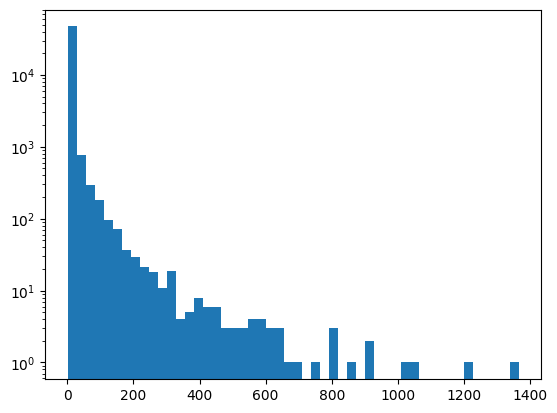

In [8]:
#Question 1

import pickle
import matplotlib.pyplot as plt
from collections import Counter

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()

counts = [count for word, count in token_freq]
plt.hist(counts, bins=50)
plt.yscale('log')
plt.show()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

Question 1: The distribution has a rightward skew. A few of the tokens appear over 1000 times, but most of the tokens only appear a few times.

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

In [9]:
# Question 2

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet('Phishing_clean.parquet')
y = df['Email Type']
X = df.drop(columns='Email Type')

# doing the 80/20 train ant test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# linear regression
model = LinearRegression().fit(X_train, y_train)
print(model.score(X_train, y_train))
print(model.score(X_test, y_test))

coefs = pd.Series(model.coef_, index=X.columns)
top = coefs.abs().sort_values(ascending=False).head(10).index
print(coefs[top])

0.7687875341139676
0.655923984746692
{text-decoration:    1.069928
background-image:   -0.896583
none;               -0.835839
localized            0.763722
{color:             -0.680250
thermal              0.652498
aging                0.650395
helvetica,           0.626287
cnet                -0.535749
group:               0.526756
dtype: float64


Question 2: the r squared for the training is about 0.77 and the test r quared is about 0.66. The words with the largest coefficients are text-decoration, background-image, etc.

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

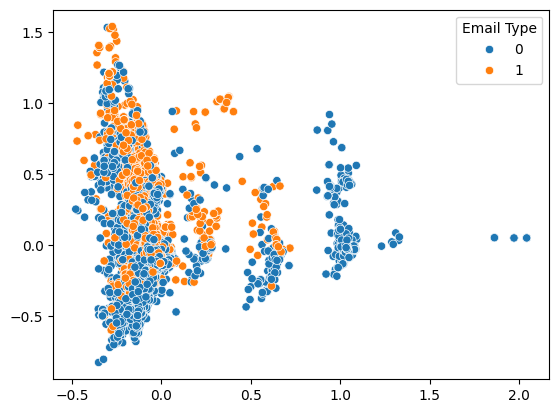

In [10]:
# Question 3

import seaborn as sns
from sklearn.decomposition import PCA

pca2 = PCA(n_components=2).fit(X)
scores = pca2.transform(X)

sns.scatterplot(x=scores[:, 0], y=scores[:, 1], hue=y)
plt.show()

Question 3: Most of the emails are around the dense cluster, and the scams (1) are concentrated toward the upper part of the cluster. The two components cant seperate the scams very well.

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [12]:
# Question 4

import seaborn as sns
from sklearn.decomposition import PCA

pca = PCA(n_components=2610).fit(X_train)
Z_train = pca.transform(X_train)
Z_test = pca.transform(X_test)

model_pc = LinearRegression().fit(Z_train, y_train)
print(model_pc.score(Z_train, y_train))
print(model_pc.score(Z_test, y_test))

0.7678719293227674
0.6584780718049501


The training r squared is still about 0.77 and the test r squared is about 0.66, which is also essentially the same as the origional data. This means that the performance barely changes.

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

The principle components are uncorrelated with eachother whereas the origional features are highly correlated. This means that we can keep the most important dirrections and drop the noisy ones, which makes less overfitting.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Carter Shaffer

**Date:** 10/21/26

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]